<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/01_mcculloch_pitts_logic_gates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 1 · McCulloch–Pitts Neurons & Logic Gates

*Neural Network Lab — lesson 1 of 8 · about 25 minutes*

### 🎯 Learning objectives
By the end of this lesson you will be able to:

1. describe the McCulloch–Pitts (MP) neuron as a weighted sum followed by a hard threshold;
2. choose weights and thresholds by hand to implement AND, OR, NOT, NAND and NOR;
3. explain geometrically why a single threshold neuron *cannot* compute XOR;
4. build XOR from a small two-layer network of MP neurons.

**Prerequisites:** basic Python and NumPy; Boolean logic (truth tables).

In [1]:
# ── Setup: runs locally and on Google Colab ──────────────────────────────
try:
    import nnlab
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## 1 · The idea

In 1943 Warren McCulloch and Walter Pitts proposed the first mathematical model of a neuron.
It ignores almost all of biology and keeps just one idea: **a neuron adds up its inputs and fires
if the total is large enough.**

$$
net = \sum_{i=1}^{n} w_i x_i, \qquad
y = \begin{cases} 1 & \text{if } net \ge \theta \\ 0 & \text{otherwise} \end{cases}
$$

* $x_i \in \{0, 1\}$ are the binary inputs,
* $w_i$ are fixed **weights** (positive = excitatory, negative = inhibitory),
* $\theta$ is the **threshold**.

There is no learning yet — the weights are chosen *by us*. That makes the MP neuron a perfect
first model: the only question is *“which weights and threshold give the behaviour I want?”*

## 2 · Work it by hand first

Take $w_1 = w_2 = 1$. Fill in $net$ for the four input patterns:

| $x_1$ | $x_2$ | $net = x_1 + x_2$ | AND ($\theta = 2$) | OR ($\theta = 1$) |
|:-:|:-:|:-:|:-:|:-:|
| 0 | 0 | ? | ? | ? |
| 0 | 1 | ? | ? | ? |
| 1 | 0 | ? | ? | ? |
| 1 | 1 | ? | ? | ? |

The **same weights** give two different gates — only the threshold changes.
NOT, NAND and NOR are obtained by *inverting* the output of a neuron.


**❓ What are the outputs?**

<details><summary>Show answer</summary>

$net = 0, 1, 1, 2$. AND fires only when $net \ge 2$ → `0 0 0 1`. OR fires when $net \ge 1$ → `0 1 1 1`.

</details>

## 3 · The code

`nnlab.mcculloch_pitts` defines an `MPNeuron` with `weights`, a `threshold`, and an optional
`inverted` flag. The gates from the original lab are collected in `GATES`.

In [2]:
from nnlab.mcculloch_pitts import GATES, MPNeuron, truth_table, xor_network

for name, neuron in GATES.items():
    n_inputs = len(neuron.weights)
    rows = truth_table(neuron, n_inputs)
    print(f"{name:<5} w={neuron.weights}, θ={neuron.threshold}, inverted={neuron.inverted}")
    for inputs, out in rows:
        print(f"      {inputs} → {out}")

AND   w=(1, 1), θ=2, inverted=False
      (0, 0) → 0
      (0, 1) → 0
      (1, 0) → 0
      (1, 1) → 1
OR    w=(1, 1), θ=1, inverted=False
      (0, 0) → 0
      (0, 1) → 1
      (1, 0) → 1
      (1, 1) → 1
NOT   w=(1,), θ=1, inverted=True
      (0,) → 1
      (1,) → 0
NAND  w=(1, 1), θ=2, inverted=True
      (0, 0) → 1
      (0, 1) → 1
      (1, 0) → 1
      (1, 1) → 0
NOR   w=(1, 1), θ=1, inverted=True
      (0, 0) → 1
      (0, 1) → 0
      (1, 0) → 0
      (1, 1) → 0


## 4 · See it: a neuron draws a line

The neuron fires when $w_1 x_1 + w_2 x_2 \ge \theta$. The boundary $w_1 x_1 + w_2 x_2 = \theta$
is a **straight line** in the input plane: everything on one side gives 1, everything on the other
side gives 0. A function a single neuron can compute is therefore called **linearly separable**.

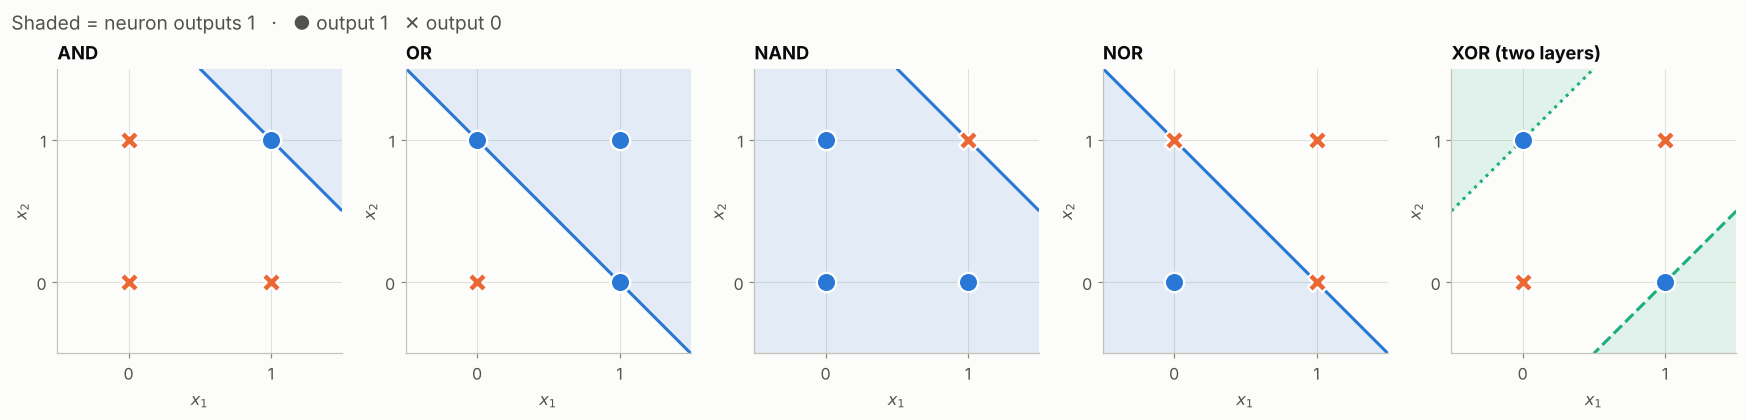

In [3]:
pts = np.array([(0, 0), (0, 1), (1, 0), (1, 1)])
grid = np.linspace(-0.5, 1.5, 300)
G1, G2 = np.meshgrid(grid, grid)


def draw_points(ax, outputs):
    for (x1, x2), out in zip(pts, outputs):
        ax.scatter(x1, x2, s=160, zorder=3,
                   marker="o" if out else "X",
                   color=PALETTE[0] if out else PALETTE[1],
                   edgecolor="white", linewidth=1.5)
    ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xticks=[0, 1], yticks=[0, 1],
           xlabel="$x_1$", ylabel="$x_2$", aspect="equal")


fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, name in zip(axes, ["AND", "OR", "NAND", "NOR"]):
    n = GATES[name]
    fires = (n.weights[0] * G1 + n.weights[1] * G2 >= n.threshold) != n.inverted
    ax.contourf(G1, G2, fires, levels=[0.5, 1.5], colors=[PALETTE[0]], alpha=0.12)
    ax.contour(G1, G2, n.weights[0] * G1 + n.weights[1] * G2, levels=[n.threshold],
               colors=[PALETTE[0]], linewidths=2)
    draw_points(ax, [out for _, out in truth_table(n)])
    ax.set_title(name)

ax = axes[4]
for w, ls in [((1, -1), "--"), ((-1, 1), ":")]:
    ax.contour(G1, G2, w[0] * G1 + w[1] * G2, levels=[1], colors=[PALETTE[2]], linewidths=2, linestyles=ls)
xor_region = (G1 - G2 >= 1) | (G2 - G1 >= 1)
ax.contourf(G1, G2, xor_region, levels=[0.5, 1.5], colors=[PALETTE[2]], alpha=0.12)
draw_points(ax, [out for _, out in truth_table(xor_network)])
ax.set_title("XOR (two layers)")

fig.suptitle("Shaded = neuron outputs 1   ·   ● output 1   ✕ output 0", x=0.01, ha="left", color="#52514e")
fig.tight_layout()
plt.show()

## 5 · Why XOR needs a second layer

Look at the XOR panel: the two ● points sit on opposite corners. **No single straight line** can put
both ● on one side and both ✕ on the other — XOR is *not linearly separable*. This observation,
made famous by Minsky & Papert (1969), is why single-layer networks are limited.

The fix is to decompose the problem:

$$
\text{XOR}(x_1, x_2) = \underbrace{(x_1 \land \lnot x_2)}_{z_1:\ w=(1,-1),\ \theta=1}
\;\lor\; \underbrace{(\lnot x_1 \land x_2)}_{z_2:\ w=(-1,1),\ \theta=1}
$$

Each hidden neuron draws one of the two lines (dashed and dotted above); the output neuron is an
OR gate that fires if *either* hidden neuron fires.

In [4]:
from nnlab.mcculloch_pitts import XOR_HIDDEN

print(" x1 x2 | z1 z2 | XOR")
for (x1, x2), out in truth_table(xor_network):
    z1, z2 = (neuron(x1, x2) for neuron in XOR_HIDDEN)
    print(f"  {x1}  {x2} |  {z1}  {z2} |  {out}")

 x1 x2 | z1 z2 | XOR
  0  0 |  0  0 |  0
  0  1 |  0  1 |  1
  1  0 |  1  0 |  1
  1  1 |  0  0 |  0


## 6 · Try it yourself

1. Design a single MP neuron for the **implication** $x_1 \Rightarrow x_2$ (false only for $x_1=1, x_2=0$).
2. Build a 3-input **majority** gate (outputs 1 when at least two inputs are 1).
3. Build **XNOR** with a two-layer network.

In [5]:
# Exercise 1 — replace the weights and threshold
implication = MPNeuron(weights=(0, 0), threshold=0)
print(truth_table(implication))   # target: [((0,0),1), ((0,1),1), ((1,0),0), ((1,1),1)]

# Exercise 2
majority = MPNeuron(weights=(0, 0, 0), threshold=0)
print([out for _, out in truth_table(majority, n_inputs=3)])  # target: [0,0,0,1,0,1,1,1]

[((0, 0), 1), ((0, 1), 1), ((1, 0), 1), ((1, 1), 1)]
[1, 1, 1, 1, 1, 1, 1, 1]


**❓ Exercise answers**

<details><summary>Show answer</summary>

1. $w = (-1, 1)$, $\theta = 0$: the net is negative only for $(1, 0)$.
2. $w = (1, 1, 1)$, $\theta = 2$.
3. XNOR is NOT(XOR): reuse the two hidden neurons and use a **NOR** gate as the output neuron.

</details>

**❓ Why can't we just add more inputs to one neuron to get XOR of two variables?**

<details><summary>Show answer</summary>

Extra inputs that are constant only shift the line; the decision boundary of one threshold neuron is always a single hyperplane, and the XOR classes are not separable by any hyperplane in the $(x_1, x_2)$ plane. You need a non-linear feature — such as the output of another neuron.

</details>

## 📌 Summary

- An MP neuron computes a weighted sum and compares it to a threshold.
- Its decision boundary is a straight line (a hyperplane in higher dimensions).
- AND, OR, NAND, NOR and NOT are linearly separable; XOR is not.
- Stacking neurons into layers lets us carve out non-linear regions — the key idea behind every deep network.

**Next →** [Lesson 2 · Activation Functions](02_activation_functions.ipynb)

---

#### References
- McCulloch, W. S., & Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *Bulletin of Mathematical Biophysics*, 5(4), 115–133.
- Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.